Student Performance – Linear Regression                              
Kaggle link : https://www.kaggle.com/datasets/nikhil7280/student-performance-multiple-linear-regression

In [849]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [850]:
df=pd.read_csv("Student_Performance.csv")
print(df.head(11))

    Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0               7               99                        Yes            9   
1               4               82                         No            4   
2               8               51                        Yes            7   
3               5               52                        Yes            5   
4               7               75                         No            8   
5               3               78                         No            9   
6               7               73                        Yes            5   
7               8               45                        Yes            4   
8               5               77                         No            8   
9               4               89                         No            4   
10              8               91                         No            4   

    Sample Question Papers Practiced  Performance Index  
0    

Data Preprocessing & Cleaning:

In [851]:
df.shape

(10000, 6)

In [852]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB


In [853]:
df.dtypes

Hours Studied                         int64
Previous Scores                       int64
Extracurricular Activities              str
Sleep Hours                           int64
Sample Question Papers Practiced      int64
Performance Index                   float64
dtype: object

In [854]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [855]:
print('null values:')
df.isnull().sum()

null values:


Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [856]:
print(f'number of duplicate rows: {df.duplicated().sum()}')

number of duplicate rows: 127


In [857]:
df = df.drop_duplicates()
print(f'number of duplicate rows after cleaning: {df.duplicated().sum()}')

number of duplicate rows after cleaning: 0


In [858]:
df["Extracurricular Activities"].value_counts()

Extracurricular Activities
No     4986
Yes    4887
Name: count, dtype: int64

In [859]:
#Encode Extracurricular Activities (0 -> No , 1 -> Yes)
df['Extracurricular Activities']=df['Extracurricular Activities'].map({'No':0,'Yes':1})
df["Extracurricular Activities"].value_counts()

Extracurricular Activities
0    4986
1    4887
Name: count, dtype: int64

In [860]:
df=df.rename(columns={"Sample Question Papers Practiced": "Sample_Papers_Practiced",
    "Performance Index": "Final_Score"
})
df.columns


Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample_Papers_Practiced', 'Final_Score'],
      dtype='str')

Exploratory Data Analysis (EDA)

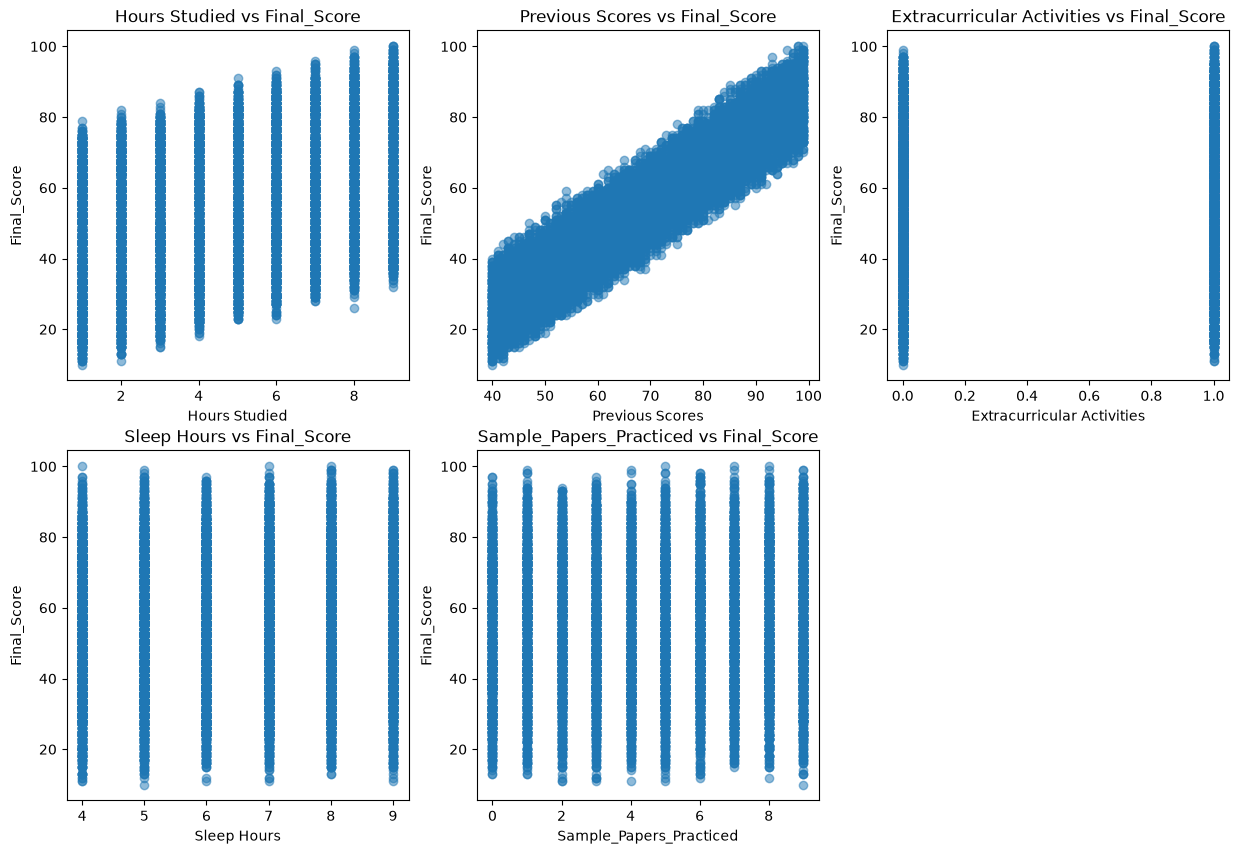

In [861]:
features = [
    "Hours Studied",
    "Previous Scores",
    "Extracurricular Activities",
    "Sleep Hours",
    "Sample_Papers_Practiced"
]

plt.figure(figsize=(15, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 3, i)
    plt.scatter(df[feature], df["Final_Score"], alpha=0.5)
    plt.xlabel(feature)
    plt.ylabel("Final_Score")
    plt.title(f"{feature} vs Final_Score")

plt.show()

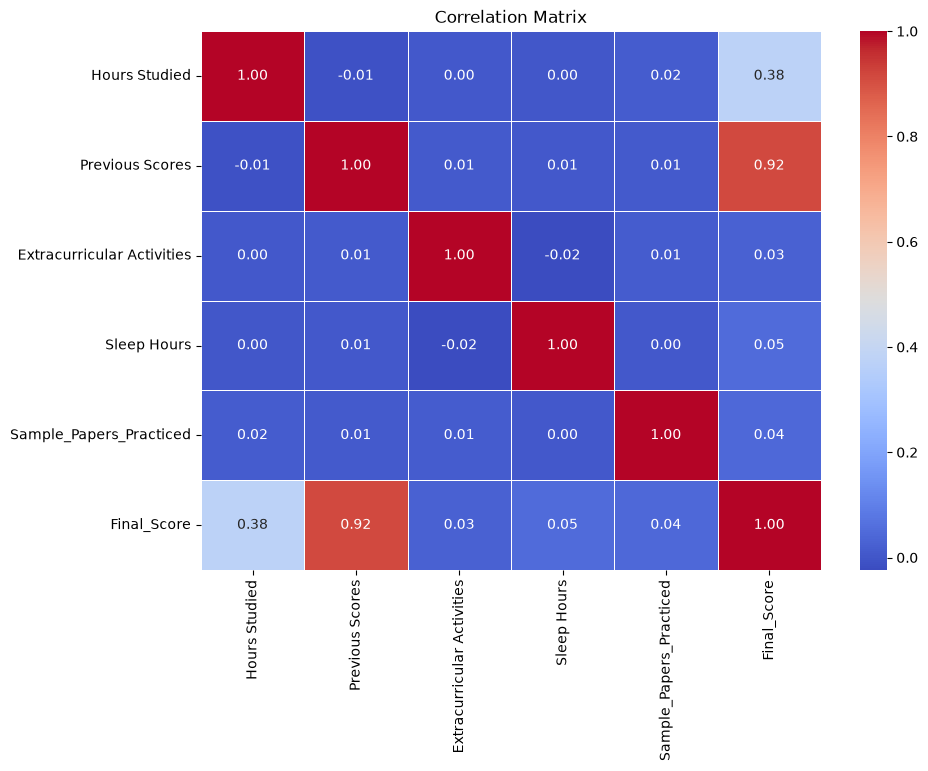

In [862]:
correlation_matrix = df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.show()

Model Training & Prediction

In [863]:
X=df.drop(columns='Final_Score') #X -> features
Y=df['Final_Score'] #Y -> target column

In [864]:
print(X.shape)
print(Y.shape)

(9873, 5)
(9873,)


In [865]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [866]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train,Y_train)

#predict on X_test and store the result in y_predict
y_predict = model.predict(X_test)

In [867]:
dd=pd.DataFrame({
    "Actual Score": Y_test.values,
    "Predicted Score": y_predict
})
print(dd.head(21))




    Actual Score  Predicted Score
0           47.0        46.480013
1           76.0        80.285379
2           62.0        61.065188
3           23.0        22.706315
4           76.0        74.836868
5           83.0        84.194968
6           60.0        61.993141
7           51.0        50.337443
8           38.0        38.898681
9           58.0        55.753202
10          48.0        49.501278
11          62.0        64.076698
12          54.0        55.783705
13          47.0        43.692546
14          55.0        59.091863
15          54.0        55.886224
16          86.0        86.349914
17          31.0        28.220283
18          35.0        36.004506
19          38.0        40.078349
20          31.0        37.197453


In [868]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(Y_test, y_predict)
print("Mean Squared Error:", mse)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)
mae = mean_absolute_error(Y_test, y_predict)
print("Mean Absolute Error:", mae)

Mean Squared Error: 4.305900938538477
Root Mean Squared Error: 2.0750664901488043
Mean Absolute Error: 1.6469703984255568


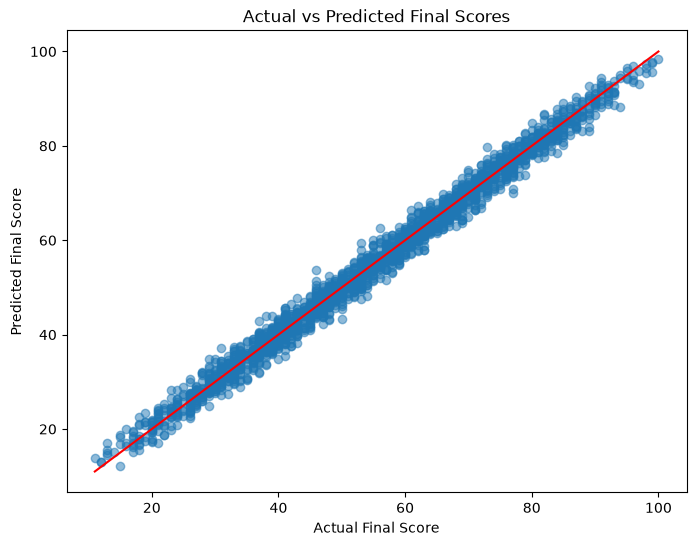

In [869]:
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, y_predict, alpha=0.5)
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color="red",
    
)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Actual vs Predicted Final Scores")

plt.show()

In [870]:
from sklearn.metrics import r2_score
r2 = r2_score(Y_test, y_predict)
print("R² Score:", r2)

R² Score: 0.9884301209927054


train the model with only two features that have a good correlation with Final_Score (target value) trying to see if fewer features can match the full model

In [871]:
modelB=LinearRegression()
selected_features = ["Previous Scores","Hours Studied",]

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

In [872]:
modelB.fit(X_train_selected, Y_train)
y_pred_selected = modelB.predict(X_test_selected)

In [873]:
mse_selected = mean_squared_error(Y_test, y_pred_selected)
rmse_selected = np.sqrt(mse_selected)
mae_selected = mean_absolute_error(Y_test, y_pred_selected)


In [874]:
comparison_models = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE"],
    "Model A - All Features": [mse, rmse, mae],
    "Model B - Two Features": [mse_selected,rmse_selected,mae_selected]
})
comparison_models

,Metric,Model A - All Features,Model B - Two Features
0,MSE,4.305901,5.573764
1,RMSE,2.075066,2.360882
2,MAE,1.646970,1.879831


In [875]:
from sklearn.metrics import r2_score
r2 = r2_score(Y_test, y_pred_selected)
print("R² Score:", r2)

R² Score: 0.9850233951895029


in conclusion , first model was better in accuracy and error values so the features that were removed shouldn't be removed as they have good effect in the model and predicted values   